# v3 - 5. Final test (run ONCE)
Trains every model on all development buckets with the frozen settings and scores the locked test buckets. A second run is refused; if it already ran, the saved results are loaded.

**What to quote as the TRUE accuracy:** the *hard regime* row (content only), with its family-bootstrap interval. The *public regime* number is optimistic because a source's style reveals its class. Overall accuracy mixes the two.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v3"          # selects the strict "true accuracy" study (v3); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
from toadwatch import config as C, workflow_v3 as W, protocol_v3 as P, charts_v3 as CH, reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v3 | seed: 2028 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v3


In [2]:
out = W.final_test()
res = out['results']
print('ceilings on the test buckets:', {k: round(v, 3) for k, v in out['ceilings'].items()})
res[['n', 'accuracy', 'acc_ci_low', 'acc_ci_high', 'f1', 'balanced_accuracy', 'hard_accuracy', 'hard_acc_ci_low', 'hard_acc_ci_high', 'public_accuracy']].round(3)

ceilings on the test buckets: {'majority_class': 0.601, 'call_oracle': 0.849, 'message_oracle': 0.849, 'both_channels_oracle': 1.0}


,n,accuracy,acc_ci_low,acc_ci_high,f1,balanced_accuracy,hard_accuracy,hard_acc_ci_low,hard_acc_ci_high,public_accuracy
variant,,,,,,,,,,
call_only,889,0.807,0.765,0.849,0.789,0.823,0.655,0.486,0.835,0.836
message_only,889,0.731,0.699,0.760,0.710,0.747,0.766,0.709,0.828,0.724
combined_early,889,0.872,0.846,0.899,0.851,0.879,0.772,0.674,0.874,0.891
combined_stacked,889,0.866,0.837,0.895,0.846,0.875,0.759,0.644,0.876,0.887
call_only_text,889,0.810,0.764,0.855,0.784,0.819,0.641,0.465,0.842,0.843
message_only_text,889,0.802,0.775,0.828,0.770,0.807,0.793,0.753,0.833,0.804
combined_text,889,0.910,0.873,0.944,0.887,0.906,0.724,0.620,0.854,0.946


In [3]:
res[['n', 'precision', 'recall', 'f1', 'f1_ci_low', 'f1_ci_high', 'mcc', 'roc_auc', 'tn', 'fp', 'fn', 'tp', 'p_better_than_majority_class']].round(4)

,n,precision,recall,f1,f1_ci_low,f1_ci_high,mcc,roc_auc,tn,fp,fn,tp,p_better_than_majority_class
variant,,,,,,,,,,,,,
call_only,889,0.6993,0.9042,0.7887,0.7400,0.8333,0.6329,0.8581,396,138,34,321,0.0
message_only,889,0.6234,0.8254,0.7103,0.6598,0.7530,0.4846,0.8186,357,177,62,293,0.0
combined_early,889,0.7946,0.9155,0.8508,0.8115,0.8862,0.7450,0.9493,450,84,30,325,0.0
combined_stacked,889,0.7823,0.9211,0.8461,0.8078,0.8824,0.7366,0.9539,443,91,28,327,0.0
call_only_text,889,0.7173,0.8648,0.7842,0.7313,0.8336,0.6256,0.8670,413,121,48,307,0.0
message_only_text,889,0.7178,0.8310,0.7702,0.7246,0.8071,0.6029,0.8595,418,116,60,295,0.0
combined_text,889,0.8895,0.8845,0.8870,0.8414,0.9297,0.8122,0.9717,495,39,41,314,0.0


### Accuracy by pair type
`FF` is the only fraud type. A single-channel model cannot tell `FF` from `FS` (call only) or from `SF` (message only).

In [4]:
res[[c for c in res.columns if c.startswith('acc_') and c[4:] in ('FF','FS','SF','SS')]].round(3)

,acc_FF,acc_FS,acc_SF,acc_SS
variant,,,,
call_only,0.904,0.090,0.933,0.974
message_only,0.825,0.821,0.149,0.853
combined_early,0.915,0.575,0.821,0.989
combined_stacked,0.921,0.515,0.828,0.989
call_only_text,0.865,0.149,0.963,0.992
message_only_text,0.831,0.970,0.224,0.970
combined_text,0.885,0.769,0.940,1.000


In [5]:
out['pairwise'].round(4)

,model_a,model_b,acc_diff_a_minus_b,ci_low,ci_high,bootstrap_p,a_only_right,b_only_right,mcnemar_p
0,combined_early,call_only,0.0652,0.0299,0.0992,0.000,88,30,0.000
1,combined_early,message_only,0.1406,0.1058,0.1814,0.000,171,46,0.000
2,combined_stacked,call_only,0.0596,0.0327,0.0851,0.000,77,24,0.000
3,combined_text,call_only_text,0.1001,0.0752,0.1267,0.000,102,13,0.000
4,combined_text,message_only_text,0.1080,0.0688,0.1508,0.000,140,44,0.000
5,combined_text,combined_early,0.0382,0.0023,0.0689,0.039,68,34,0.001


`acc_diff_a_minus_b` > 0 means model *a* is better; if its interval contains 0 the models are not distinguishable.

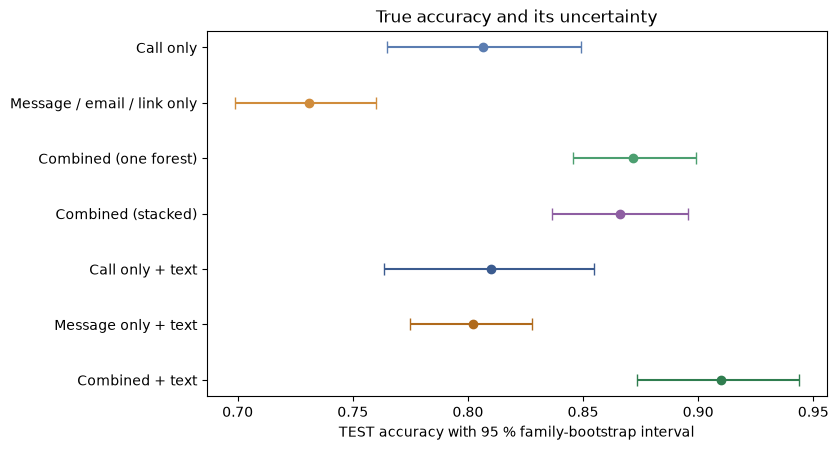

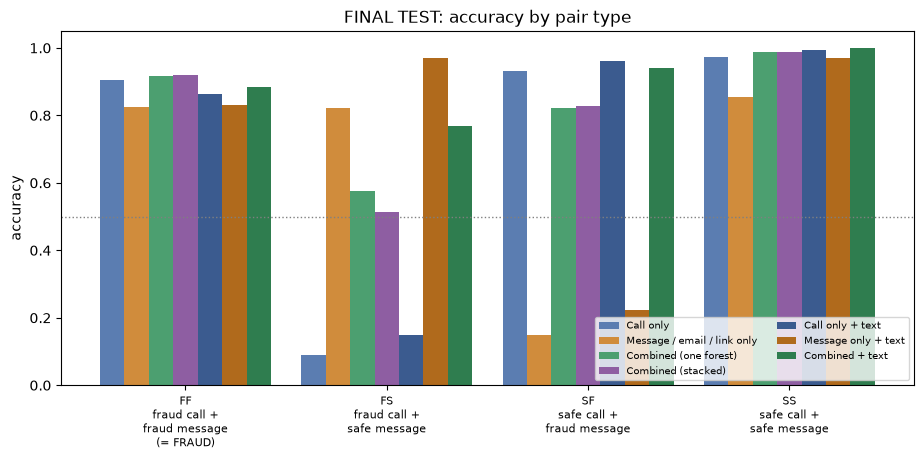

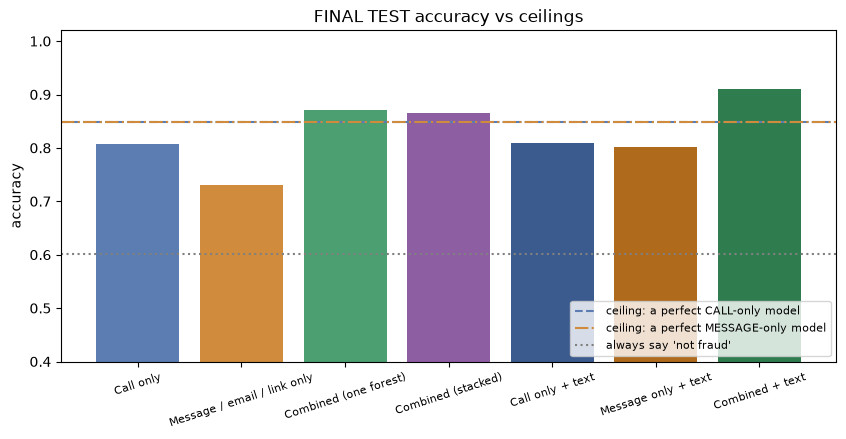

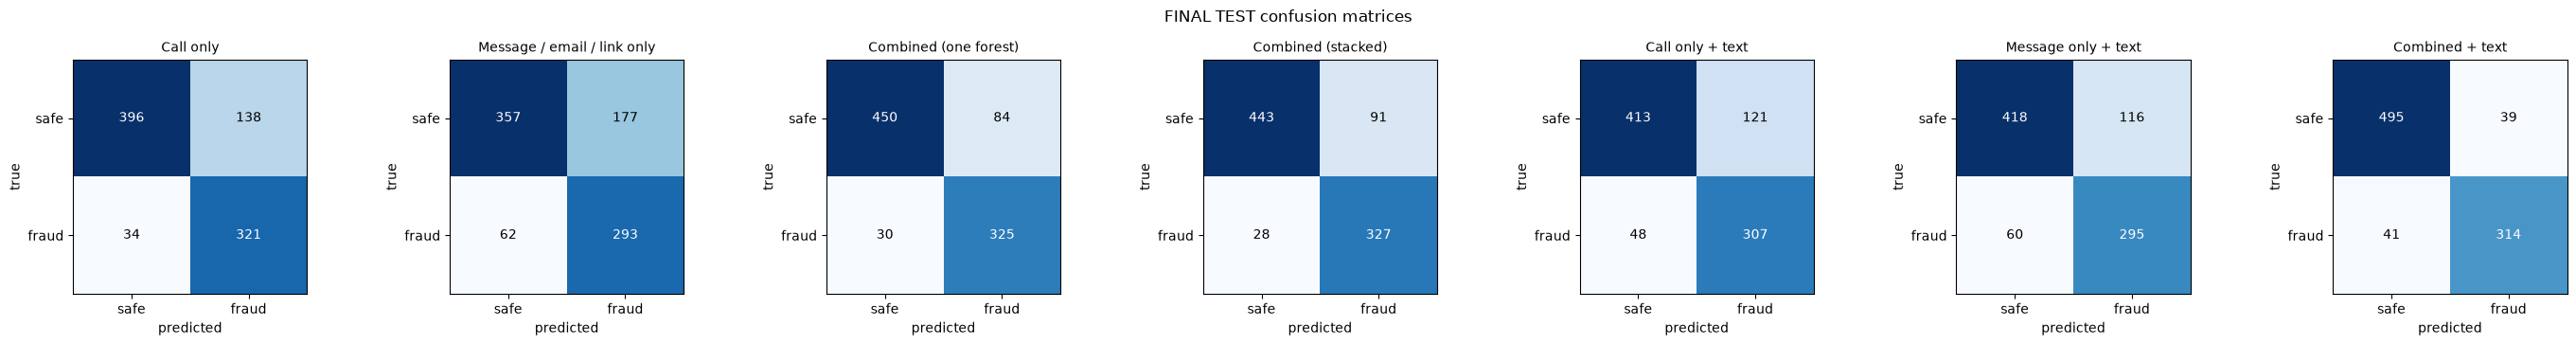

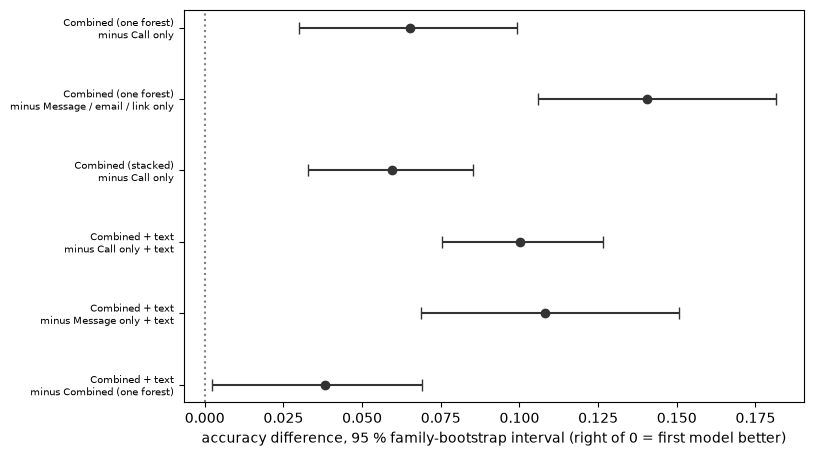

In [6]:
CH.plot_acc_ci(res, 'v3_10_test_acc_ci'); CH.plot_pair_type_accuracy(res, 'FINAL TEST: accuracy by pair type', 'v3_11_test_pair_type')
CH.plot_accuracy_vs_ceilings(res, out['ceilings'], 'FINAL TEST accuracy vs ceilings', 'v3_12_test_vs_ceilings'); R.plot_confusion_matrices(res, 'FINAL TEST confusion matrices', 'v3_13_test_confusion'); CH.plot_pairwise_acc(out['pairwise'], 'v3_14_test_pairwise'); plt.show()

In [7]:
e = out['predictions']; ch = 'combined_text' if 'pred_combined_text' in e else 'pred_combined_early'
ch = 'pred_' + ('combined_text' if 'pred_combined_text' in e else 'combined_early') if not ch.startswith('pred_') else ch
err = e[(e.label != e[ch])]
print(len(err), 'errors of', ch, '; by pair type:', err.pair_type.value_counts().to_dict(), '; by regime:', err.regime.value_counts().to_dict())
err[['regime', 'pair_type', 'label', 'call_text', 'msg_text']].head(8)

80 errors of pred_combined_text ; by pair type: {'FF': 41, 'FS': 31, 'SF': 8} ; by regime: {'public': 40, 'hard': 40}


,regime,pair_type,label,call_text,msg_text
3,public,FS,0,"Hello, is this Mr. Johnson? Yes, that's me. Who's calling? This is Officer David from the Social Security Administra...",You flippin your shit yet?
10,public,FS,0,this is Susie calling with the Vehicle Service Department. We are calling about your vehicle's manufacturer's warran...,Nicor Estimated Imbalance Thru 10/16/01\nPlease see attached. \n\nKaren A. Clapper\nEnron Gas Logistics - NNG\nkaren...
63,public,FS,0,"Hello. Hello, this is Alex from TechShield Solutions. We've been monitoring your internet activity and it appears th...",El chico de 2 oz está siendo kinda flaky pero un amigo está interesado en recoger $ &lt;#&gt; vale esta noche si es ...
64,public,FF,1,"Hello, this is Officer Johnson from the Social Security Administration. We've been trying to reach you about a suspi...","¿Sabes que en unos 40 años, tendremos miles de ancianas que corren con tatuaje?"
71,hard,FF,1,"Buenos días, le llama Lourdes del Departamento de Hacienda, unidad de reembolsos. Su expediente muestra un reembolso...",Asunto: Notificación de Hacienda\nEstimado contribuyente:\nSu planilla presenta un ajuste que debe atenderse para ev...
76,public,FS,0,"Hello. Hello, is this Mr. Harrison? My name is Officer Thompson from the Social Security Administration. I'm calling...","quick question on Transwestern Cash Flows\nShelley,\n\nI'm working with Kevin Howard on the Revolver and I'm looking..."
117,hard,FF,1,"Buenas tardes, mi nombre es Marisol, llamo de la división de reintegros. Su expediente muestra un reembolso de $49.9...",Asunto: Reembolso de contribuciones disponible\nEstimado contribuyente:\nSegún nuestros registros usted tiene un ree...
120,public,FS,0,"Hello, this is John from Microsoft Technical Support. We've been getting reports of a virus on your computer. Oh, re...",Schedule Crawler: HourAhead Failure <CODESITE>\n\n\n\nStart Date: 10/8/01; HourAhead hour: 7; HourAhead schedule do...


## Generate the deliverables
Word report + PDF and PowerPoint + PDF, rebuilt from the numbers, tables and charts of the run you just made. Output folder: `report/v3/`.

In [8]:
from toadwatch import report_builder_v3
try:
    paths = report_builder_v3.build_all()
except FileNotFoundError as e:
    print('Not generated yet:', e)

/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


  report_docx  /home/rush/Downloads/Fase/ToadWatch_PR/report/v3/TOAD_TrueAccuracy_Report_v3.docx
  report_pdf   /home/rush/Downloads/Fase/ToadWatch_PR/report/v3/TOAD_TrueAccuracy_Report_v3.pdf
  slides_pptx  /home/rush/Downloads/Fase/ToadWatch_PR/report/v3/TOAD_TrueAccuracy_Slides_v3.pptx
  slides_pdf   /home/rush/Downloads/Fase/ToadWatch_PR/report/v3/TOAD_TrueAccuracy_Slides_v3.pdf
